# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import FLAIR2Dataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose

## Visualize images and masks

Total number of patches: 61686


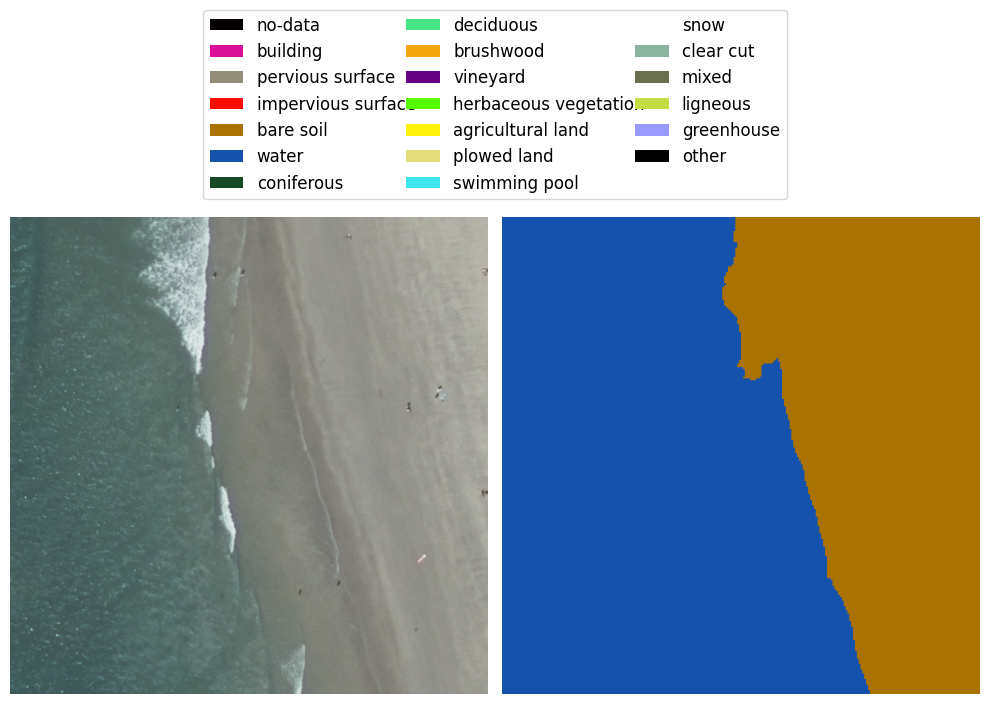

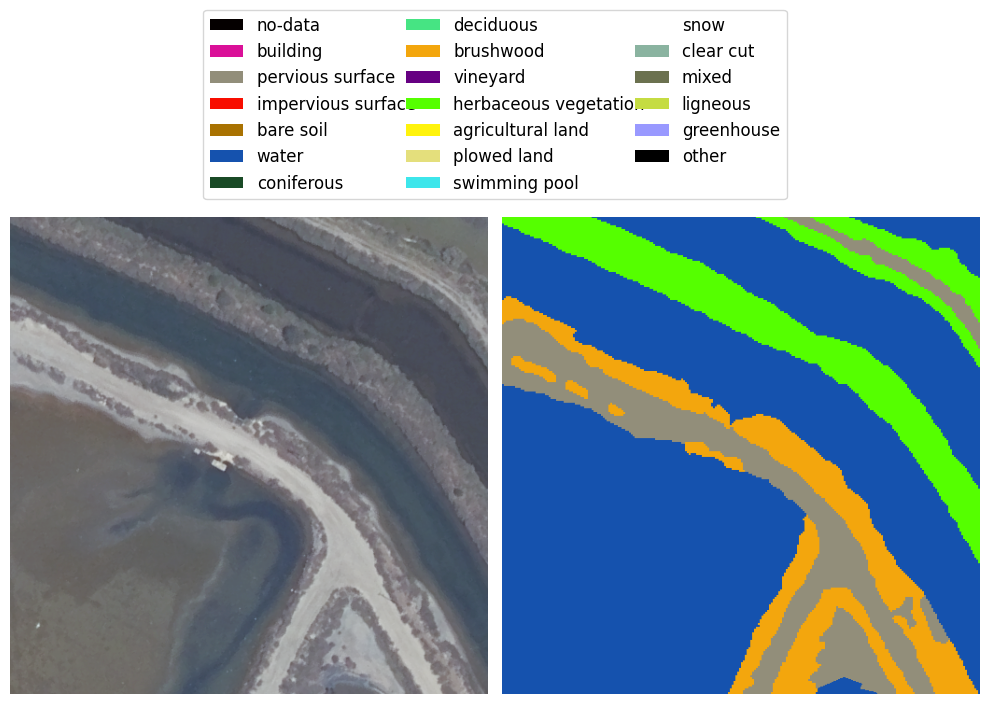

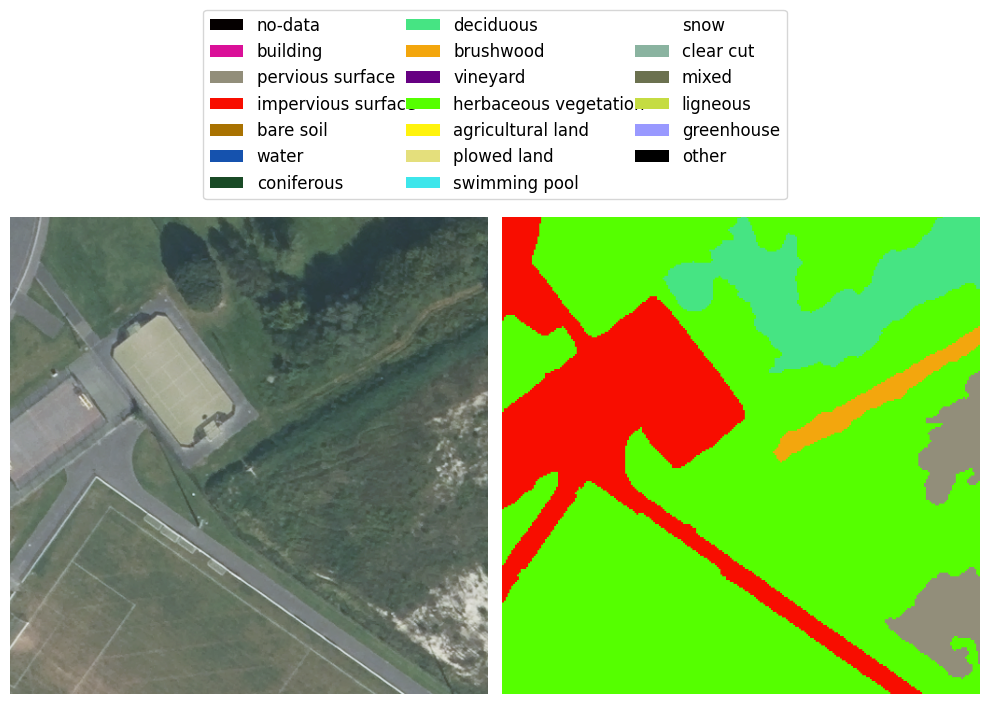

In [ ]:
dataset_config = {
    "data_dir": "./data/Flair#2/train"
}
dataset = FLAIR2Dataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(1);
dataset.show_image(250);
dataset.show_image(1500);

In [23]:
dataset.data_distribution_table()

,Number of pixels
no-data,0.000000e+00
building,1.316229e+09
pervious surface,1.334425e+09
impervious surface,2.219974e+09
bare soil,5.614355e+08
water,7.883743e+08
coniferous,4.416033e+08
deciduous,2.487350e+09
brushwood,1.123178e+09
vineyard,5.058643e+08


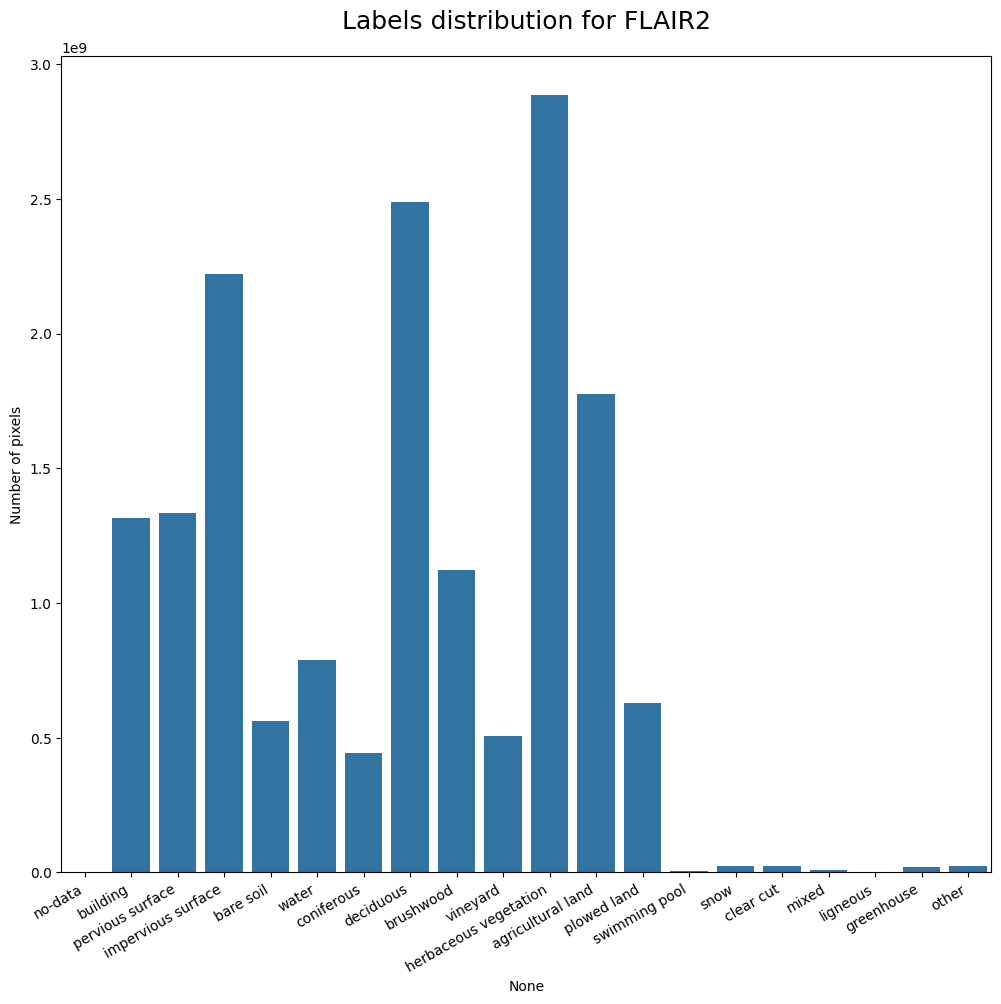

In [24]:
dataset.data_distribution_barchart();

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 23,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/Flair#2/train",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = FLAIR2Dataset(train_dataset_config)
len(train_dataset)

61686

## Create the model

In [ ]:
epochs = 10
model_directory = "./data/Flair#2"
model_config = {
    "num_classes": 20, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [6]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-04-07 06:47:44,730 INFO Starting training.
training: 100%|██████████| 2682/2682 [12:20<00:00,  3.62it/s]
2025-04-07 07:00:04,970 INFO epoch: 1, time: 740, loss:  0.39193
testing on train set: 100%|██████████| 2682/2682 [12:57<00:00,  3.45it/s]
2025-04-07 07:13:05,152 INFO IOU:0.5889580694652449, IOU mean:0.35965796123465615, IOU per Class:[0.         0.72058389 0.55768562 0.66754289 0.55498678 0.79050069
 0.41915372 0.66691005 0.3759588  0.80600533 0.481939   0.57846798
 0.57342448 0.         0.         0.         0.         0.
 0.         0.        ]
training: 100%|██████████| 2682/2682 [12:21<00:00,  3.62it/s]
2025-04-07 07:25:26,527 INFO epoch: 2, time: 741, loss:  0.25890
testing on train set: 100%|██████████| 2682/2682 [11:44<00:00,  3.81it/s]
2025-04-07 07:37:11,010 INFO IOU:0.6012392807332754, IOU mean:0.3627969063112778, IOU per Class:[0.         0.72326679 0.53193903 0.65095071 0.47409166 0.7971261
 0.42078235 0.68086273 0.41943257 0.79448333 0.51042935 0.64639172
 0.6061

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 4,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/Flair#2/val",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = FLAIR2Dataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/Flair#2/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

15700


2025-04-07 10:48:49,742 INFO Loading checkpoint /home/dragik/data/FAIR_EO/Flair#2/checkpoint.pth.tar
2025-04-07 10:48:50,212 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/Flair#2/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 3925/3925 [03:00<00:00, 21.79it/s]


[{'IOU': 0.532447776522902,
  'IOU mean': 0.32137085033774787,
  'IOU per Class': array([0.        , 0.72056634, 0.4783729 , 0.66994157, 0.57290342,
         0.81356149, 0.26728531, 0.58118169, 0.32270471, 0.7929408 ,
         0.43861329, 0.39439997, 0.37494551, 0.        , 0.        ,
         0.        , 0.        , 0.        , 0.        , 0.        ])}]

## Predictions

2025-04-07 10:52:37,322 INFO Loading checkpoint /home/dragik/data/FAIR_EO/Flair#2/checkpoint.pth.tar
2025-04-07 10:52:37,724 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/Flair#2/checkpoint.pth.tar at epoch 11


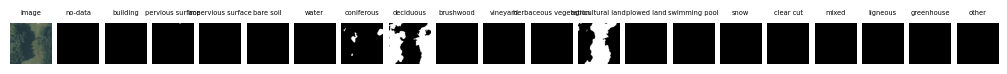

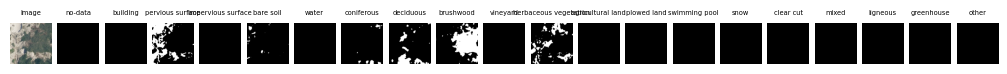

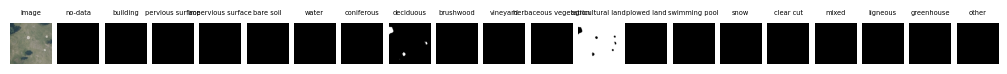

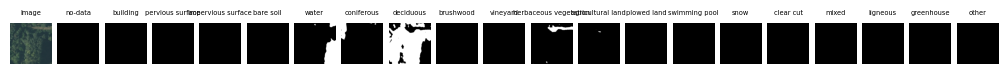

In [ ]:
model_path = "./data/Flair#2/checkpoint.pth.tar"
labels = ["no-data","building","pervious surface","impervious surface","bare soil","water","coniferous","deciduous","brushwood","vineyard","herbaceous vegetation","agricultural land","plowed land","swimming pool","snow","clear cut","mixed","ligneous","greenhouse","other"]
transform = MinMaxNormTranspose()
model.load_model(model_path)
plt.rcParams.update({'font.size': 4})

image = image_loader('./data/Flair#2/test/images/IMG_056465.tif')
image = image[:,:,0:3]
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/Flair#2/test/images/IMG_056470.tif')
image = image[:,:,0:3]
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/Flair#2/test/images/IMG_056481.tif')
image = image[:,:,0:3]
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/Flair#2/test/images/IMG_056486.tif')
image = image[:,:,0:3]
fig = model.predict_masks(image, labels, transform)